# M2: WERM versus WERM adjusted

Two paired experiments, each with **100 trials at each** $\delta=n/p\in\{1.5,3.5,7.5,11.5\}$,
$p=100$. Only WERM and WERM adjusted are compared.

The original M2 data generator is retained: `SparseDiffSignal(var_1=8,
sigma_w=sqrt(400*delta), alpha=0.3, L=4)`, independent Gaussian covariates
$X_{ij}\sim N(0,1/n)$, and Gaussian noise with standard deviation $\sqrt{0.1}$.
The prior rescales perturbed coefficients to preserve marginal variance, exactly as in M2.
Within each trial both methods receive identical data, marginal weights, and CV folds.

- **Unknown count:** true changes at $(0.2,0.5)n$; candidates have 1–4 segments.
  Each method independently selects its count with the original M2 interlaced 10-fold CV.
- **Known count:** exactly three changes at $(0.25,0.45,0.7)n$; fixed $L=4$, no CV.

All fits use unpenalized squared loss, no intercept, and no partition penalty.
Minimum internal-boundary separation follows M2's helper:
$\max(\lceil n_{\mathrm{fit}}/50\rceil,\lfloor n_{\mathrm{fit}}/40\rfloor,1)$.
The native DP does not impose that separation on the two end segments.
The existing experiments and their saved results are not changed.

## Adjustment checked against the paper and myocardial notebook

`Myocardial Infarction Experiment - final_final.ipynb`, case A, uses
`WERM.signal_strength.empirical_adjustment`; its adjusted fit is named `V`.
This implements `eq:theta-deb-defn` and `eq:b-hat-eqn` in
`../WERM-paper/JRSSB-revision-rebuttal/JRSSB_v2.tex`:
$$\theta^{\mathrm{adj}}_{i\ell}=\hat\theta_{i\ell}
+\hat b_\ell\pi_i^{(\ell)}M'(\hat\theta_{i\ell},y_i),\qquad
\frac1n\sum_i\frac1{1+\hat b_\ell\pi_i^{(\ell)}M''(\hat\theta_{i\ell},y_i)}=1-\frac pn.$$
For this experiment $M(u,y)=(u-y)^2$, hence $M'=2(u-y)$ and $M''=2$.
The **plus sign is intentional**. The same weighted coefficient fits are used;
the adjusted method substitutes $\Theta^{\mathrm{adj}}$ for $X\hat B$ only in
the squared-loss partition search. It does not fit a new coefficient matrix.

In CV the adjustment uses only training responses and the fold-local $n/p$.
Each method's training partition is mapped back to original indices, followed
by ordinary segment coefficient refits and **absolute held-out prediction error**,
exactly as in the original M2 helper. Held-out responses never enter the adjustment.
The final search is repeated on all observations at the independently selected count.

These are empirical comparisons, not claims that the adjustment improves localization.
Finite-root failures and failed CV candidates are retained in diagnostics.
The scalar $b$ equations suffice; no full $(\Lambda,K)$ system is needed here.

In [1]:
# Run from the WeightedERM-reference directory; no earlier notebook is needed.
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from tools.m2_adjusted_experiment import (
    prepare, run_experiment, summarize, DELTAS, METHODS, FRACTIONS)

DIRECTORY, SPEC, WEIGHTS = prepare(p=100, trials=100)
JOBS = int(os.environ.get('WERM_N_JOBS','12'))
print('Checkpoints and results:', DIRECTORY)
print('Native marginal curves are frozen and shared by both methods.')

Checkpoints and results: results/M2_adjusted_comparison/ecd9d5c2529d
Native marginal curves are frozen and shared by both methods.


## 1. Unknown number of change points — separate 10-fold CV

This cell reuses completed, provenance-checked trial checkpoints. It computes missing
trials if necessary. Localization summaries exclude empty estimates and failed fits;
the table reports both explicitly. Correct-count frequencies use successful fits.

In [2]:
unknown = run_experiment('unknown', DIRECTORY, SPEC, WEIGHTS, jobs=JOBS)
unknown_summary = summarize(unknown)
unknown_summary.to_csv(DIRECTORY/'unknown_summary.csv',index=False)
display(unknown_summary.round(3))

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    1.7s
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Batch computation too fast (0.179726734157923s.) Setting batch_size=2.
[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Done  62 tasks      | elapsed:    1.8s
[Parallel(n_jobs=12)]: Batch computation too fast (0.01213693618774414s.) Setting batch_size=4.
[Parallel(n_jobs=12)]: Done  88 tasks      | elapsed:    1.9s
[Parallel(n_jobs=12)]: Batch computation too fast (0.012510299682617188s.) Setting batch_size=8.
[Parallel(n_jobs=12)]: Done 128 tasks      | elapsed:    1.9s


[Parallel(n_jobs=12)]: Done 188 tasks      | elapsed:    2.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.12065935134887695s.) Setting batch_size=16.
[Parallel(n_jobs=12)]: Done 400 out of 400 | elapsed:    2.0s finished


,delta,method,attempted,valid,failed,empty,mean_haus,median_haus,mean_count,correct_count,max_b_residual,cv_failed_folds
0,1.5,WERM,100,100,0,8,0.242,0.240,1.89,0.25,0.0,0
1,1.5,WERM adjusted,100,100,0,77,0.338,0.367,0.36,0.07,0.0,0
2,3.5,WERM,100,100,0,26,0.274,0.297,0.84,0.02,0.0,0
3,3.5,WERM adjusted,100,100,0,26,0.240,0.296,1.00,0.06,0.0,0
4,7.5,WERM,100,100,0,0,0.172,0.284,1.78,0.16,0.0,0
5,7.5,WERM adjusted,100,100,0,0,0.131,0.029,1.91,0.29,0.0,0
6,11.5,WERM,100,100,0,0,0.114,0.037,2.14,0.24,0.0,0
7,11.5,WERM adjusted,100,100,0,0,0.067,0.024,2.39,0.29,0.0,0


## Publication plotting setup

Use the final M1/M2/M3 conventions: TeX/Computer Modern, 5×4-inch line canvases,
18 pt axis labels and 14 pt ticks; means with absolute distances to the first and
third quartiles, **not confidence intervals**. Compact boxes use the shared
paper-sized style, 1.5-IQR whiskers and faint deterministic trial jitter.
Histograms use 12 data-range bins, five-fold bandwidth-selected Gaussian KDE,
truth-position ticks, and the canonical 0–18 density range (clipped peaks reported).
WERM is black; WERM adjusted is blue. Runtime is a diagnostic including each method's
own fits, CV, adjustment and final search; common marginal preparation is excluded.

In [3]:
import tools.consistent_plotting as style
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
style.OUTPUT_DIR = DIRECTORY/'figures'
style.SOURCE_HASHES.clear()
style.FIGURE_AUDIT.clear()
LABELS = (r'\textbf{WERM}', r'\textbf{WERM adjusted}')
COLORS = ('black','#4477AA')

def groups_for(payload, name, metric):
    return [[r['methods'][name][metric] for r in payload['records']
             if r['setting']==i and r['methods'][name]['error'] is None]
            for i in range(len(DELTAS))]

def plot_comparison(mode):
    payload = style.load_saved(DIRECTORY/f'{mode}.pkl')
    metrics = [('haus',r'Hausdorff dist. / $n$'), ('runtime','Runtime (s)')]
    if mode=='unknown': metrics.insert(1,('size','No. change points'))
    for metric,ylabel in metrics:
        with plt.rc_context(style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            for j,name in enumerate(METHODS):
                style.error_series(ax,DELTAS,groups_for(payload,name,metric),
                    LABELS[j],COLORS[j],('D','o')[j],('-','--')[j],scale=1)
            ax.set(xlabel=r'$\delta=n/p$',ylabel=ylabel,xticks=DELTAS)
            if metric=='size':
                ax.axhline(2,color='gray',alpha=.8,lw=2.5)
                ax.set_yticks([0,1,2,3])
            if metric=='runtime': ax.legend(loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();style.export_plot(fig,f'{mode}_{metric}_line')
        if metric=='haus':
            with plt.rc_context(style.PAPER_STYLE):
                fig,ax=style.paper_panel();rng=np.random.default_rng(42)
                for j,name in enumerate(METHODS):
                    for i,values in enumerate(groups_for(payload,name,metric)):
                        style.box_group(ax,values,3*i+j,COLORS[j],rng)
                ax.set(xticks=np.arange(4)*3+.5,xticklabels=[str(d) for d in DELTAS],
                       xlabel=r'$\delta=n/p$',ylabel=ylabel)
                ax.legend(handles=[Patch(facecolor=c,alpha=.28,label=l) for c,l in zip(COLORS,LABELS)],
                          fontsize=7,loc='best')
                style.export_plot(fig,f'{mode}_{metric}_box')
    hist=[]
    for i in range(4):
        row=[]
        for name in METHODS:
            pieces=[r['methods'][name]['cp']/r['n'] for r in payload['records']
                    if r['setting']==i and r['methods'][name]['error'] is None]
            row.append(np.concatenate(pieces) if pieces else np.array([]))
        hist.append(row)
    style.histogram_grid(hist,LABELS,COLORS,FRACTIONS[mode],f'{mode}_histograms',
        row_labels=[rf'$\delta={d:g}$' for d in DELTAS],density_label_x=.005)
    style.verify_sources()


unknown_haus_line


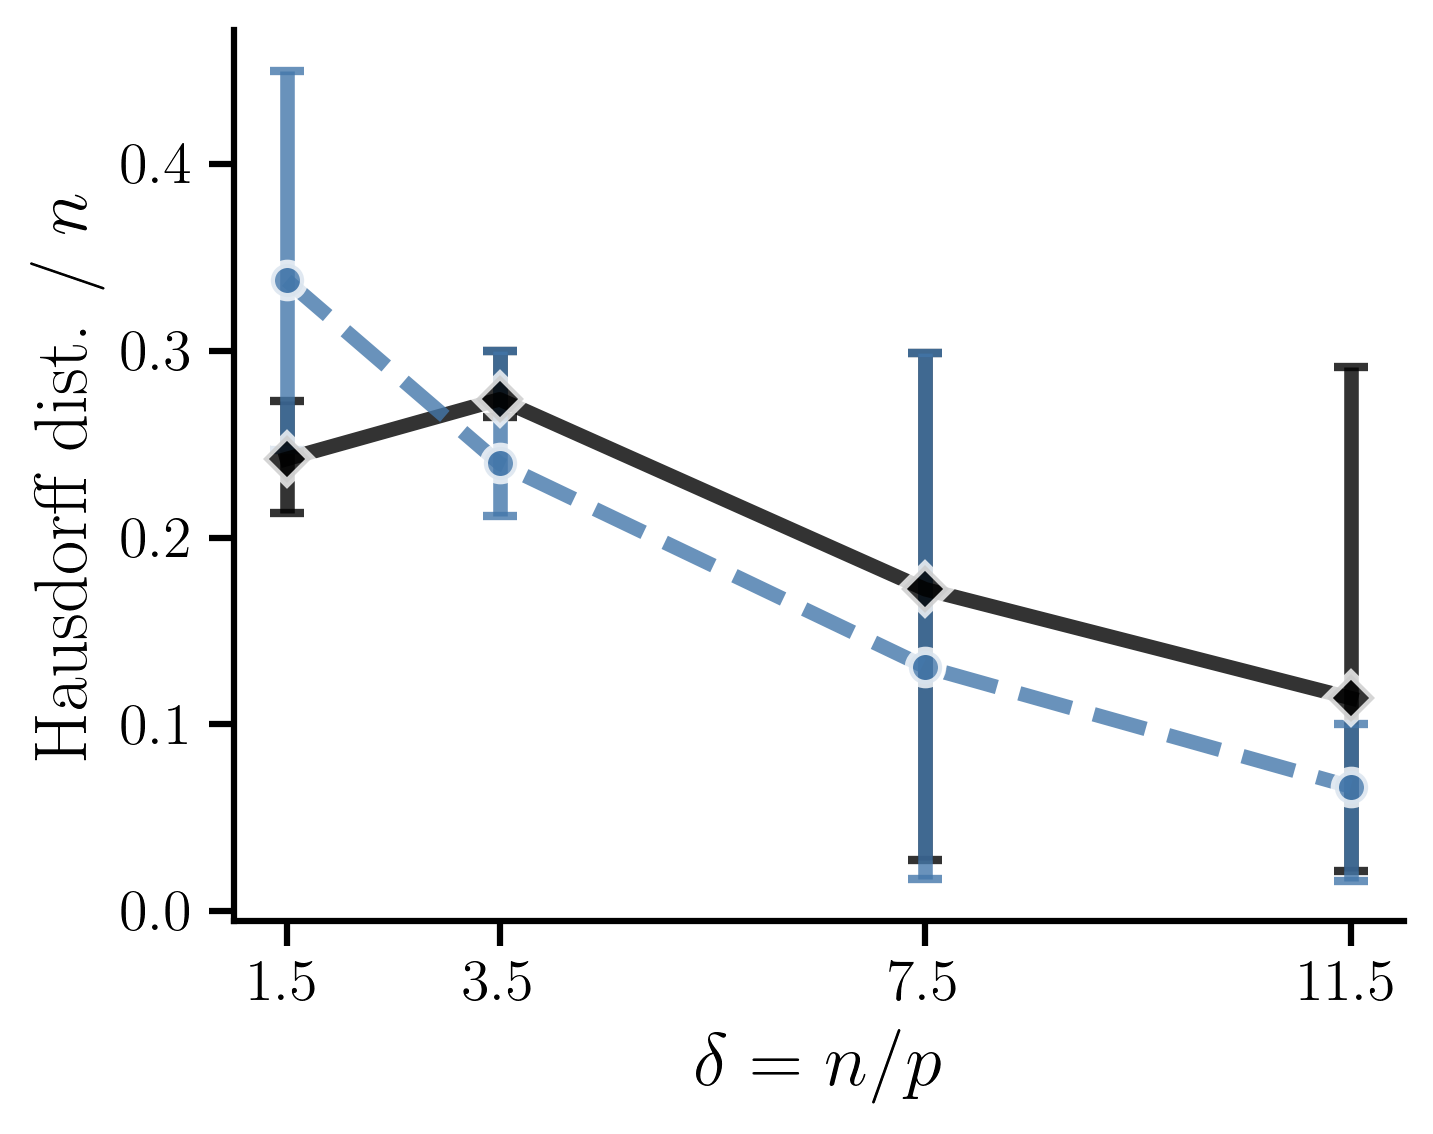

unknown_haus_box


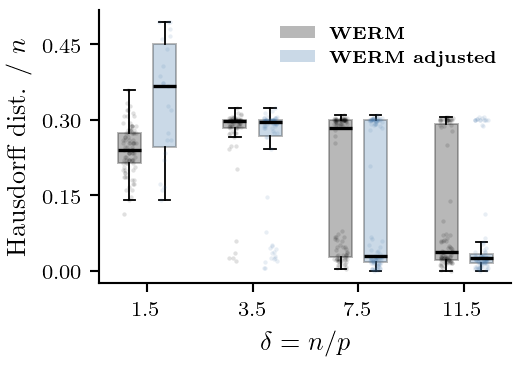

unknown_size_line


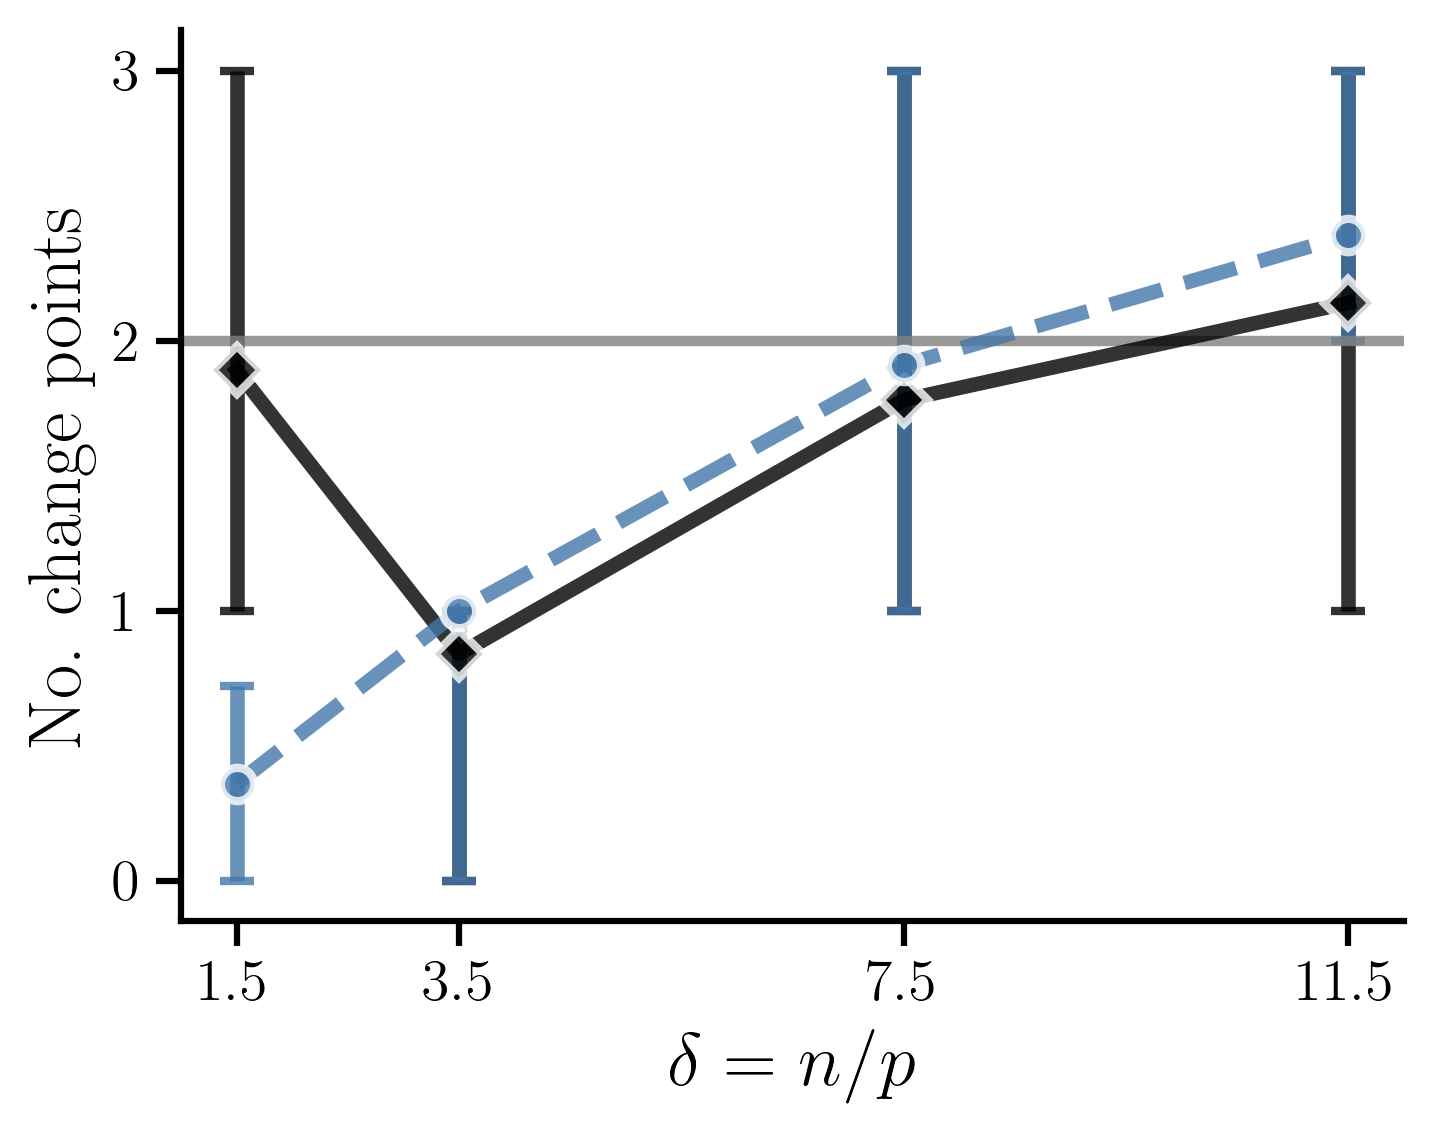

unknown_runtime_line


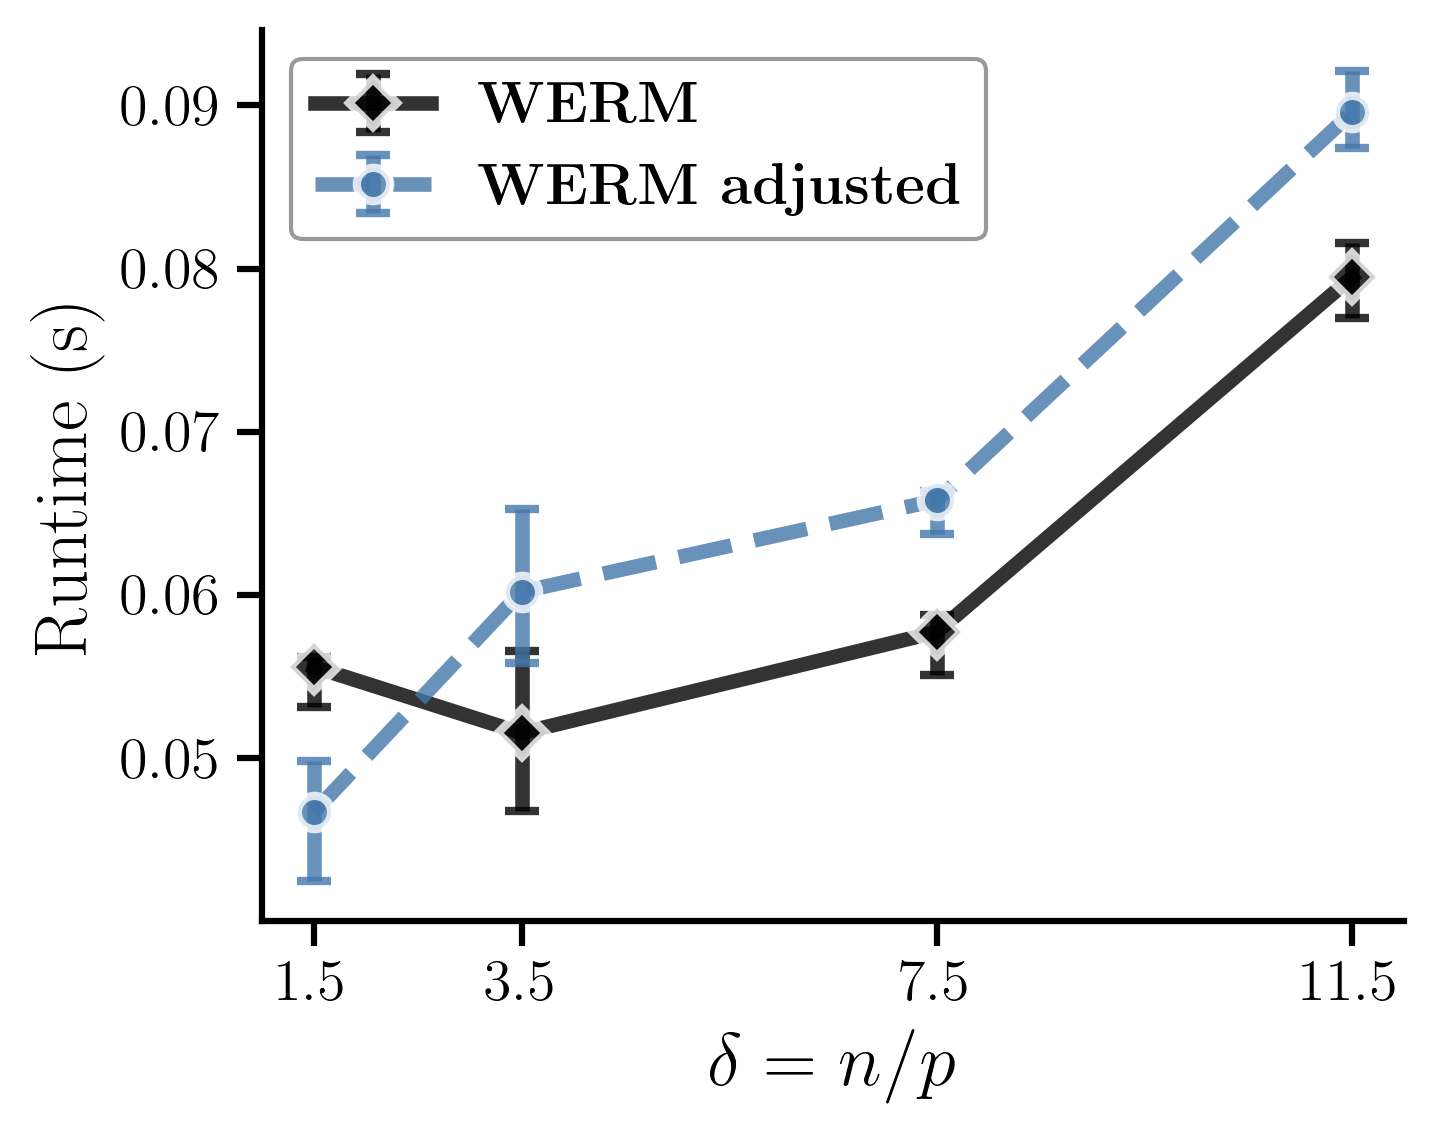

unknown_histograms: maximum density 21.95; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


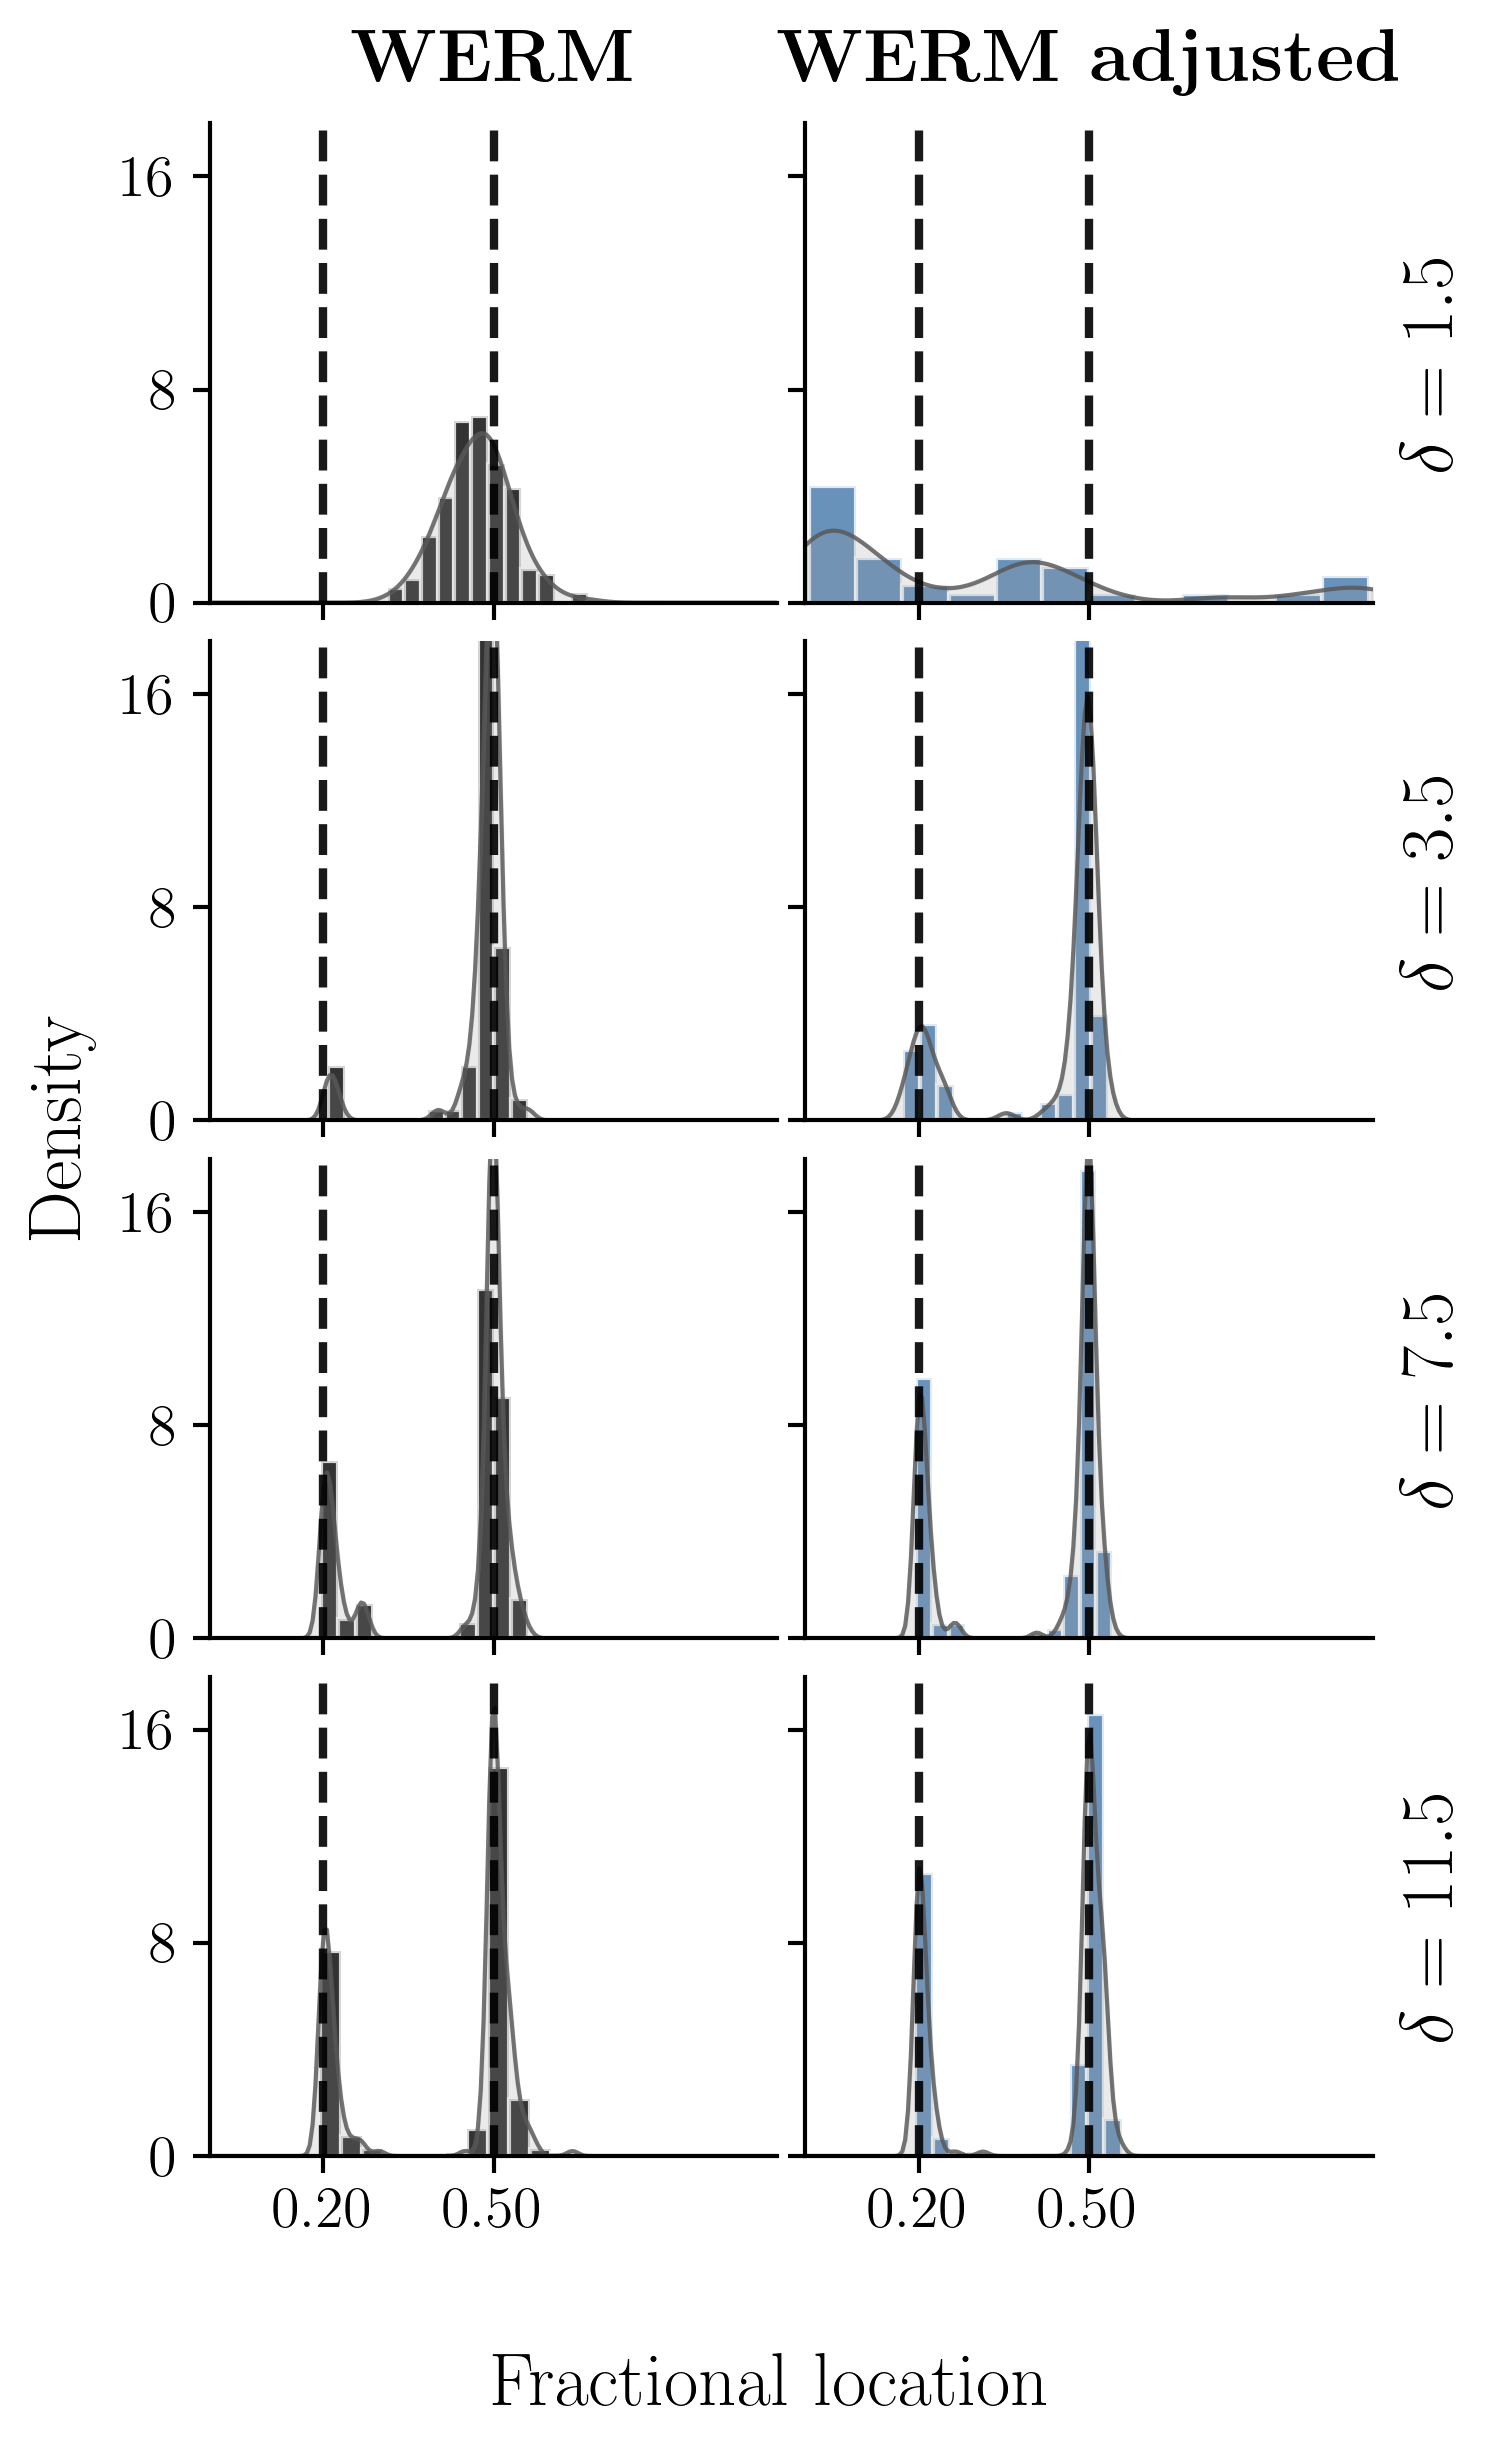

Exported 5 figures to results/M2_adjusted_comparison/ecd9d5c2529d/figures; saved inputs unchanged.


In [4]:
plot_comparison('unknown')

## 2. Known number of change points — fixed L=4, no CV

Three true changes at fractions 0.25, 0.45 and 0.7. Each method searches over
partitions with exactly four segments. This isolates the adjustment's effect on
locations without count selection.

In [5]:
known = run_experiment('known', DIRECTORY, SPEC, WEIGHTS, jobs=JOBS)
known_summary = summarize(known)
known_summary.to_csv(DIRECTORY/'known_summary.csv',index=False)
display(known_summary.round(3))
assert all(f['size']==3 for r in known['records'] for f in r['methods'].values()
           if f['error'] is None)

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.003137350082397461s.) Setting batch_size=2.
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.011478662490844727s.) Setting batch_size=4.
[Parallel(n_jobs=12)]: Done  28 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  50 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  72 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.011185407638549805s.) Setting batch_size=8.
[Parallel(n_jobs=12)]: Done 124 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.012746810913085938s.) Setting batch_size=16.
[Parallel(n_jobs=12)]: Done 184 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 304 tasks 

,delta,method,attempted,valid,failed,empty,mean_haus,median_haus,mean_count,correct_count,max_b_residual,cv_failed_folds
0,1.5,WERM,100,100,0,0,0.208,0.210,3.0,1.0,0.0,0
1,1.5,WERM adjusted,100,100,0,0,0.306,0.293,3.0,1.0,0.0,0
2,3.5,WERM,100,100,0,0,0.060,0.050,3.0,1.0,0.0,0
3,3.5,WERM adjusted,100,100,0,0,0.094,0.076,3.0,1.0,0.0,0
4,7.5,WERM,100,100,0,0,0.019,0.011,3.0,1.0,0.0,0
5,7.5,WERM adjusted,100,100,0,0,0.026,0.015,3.0,1.0,0.0,0
6,11.5,WERM,100,100,0,0,0.016,0.010,3.0,1.0,0.0,0
7,11.5,WERM adjusted,100,100,0,0,0.021,0.011,3.0,1.0,0.0,0


known_haus_line


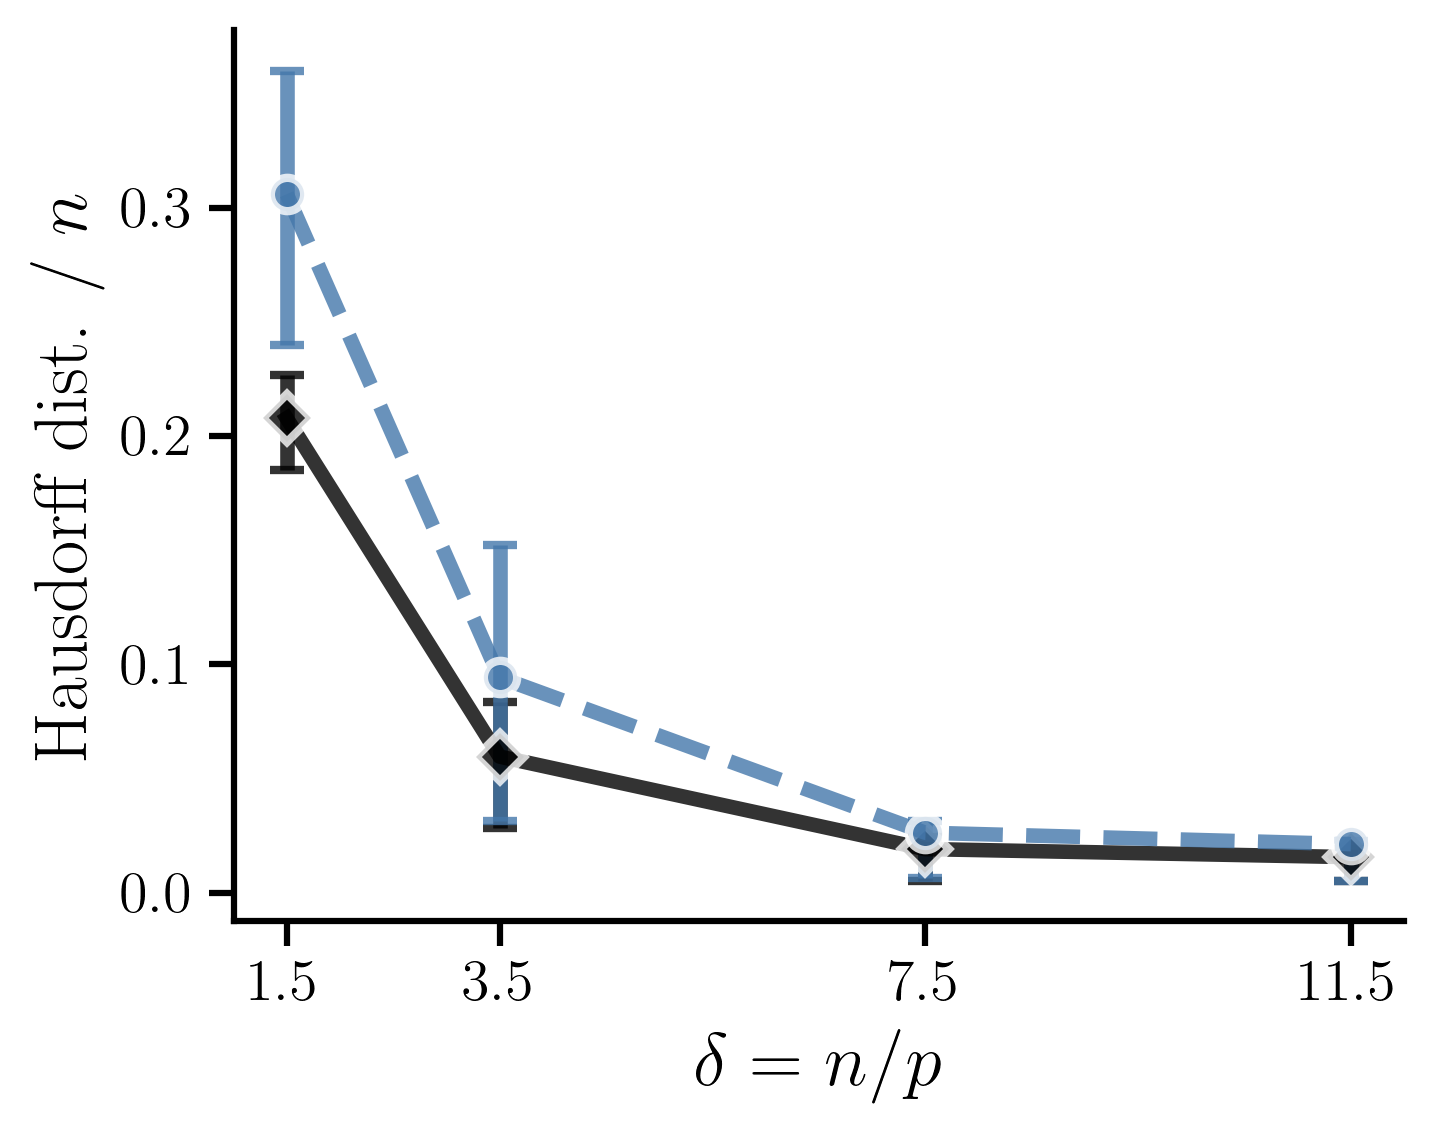

known_haus_box


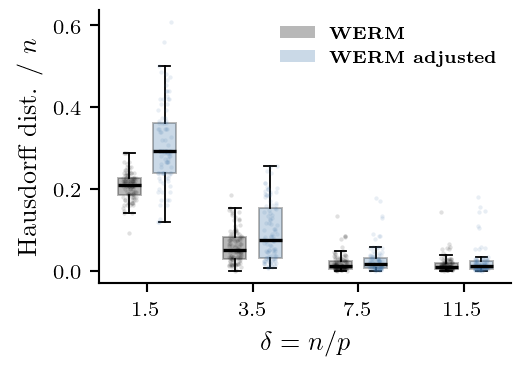

known_runtime_line


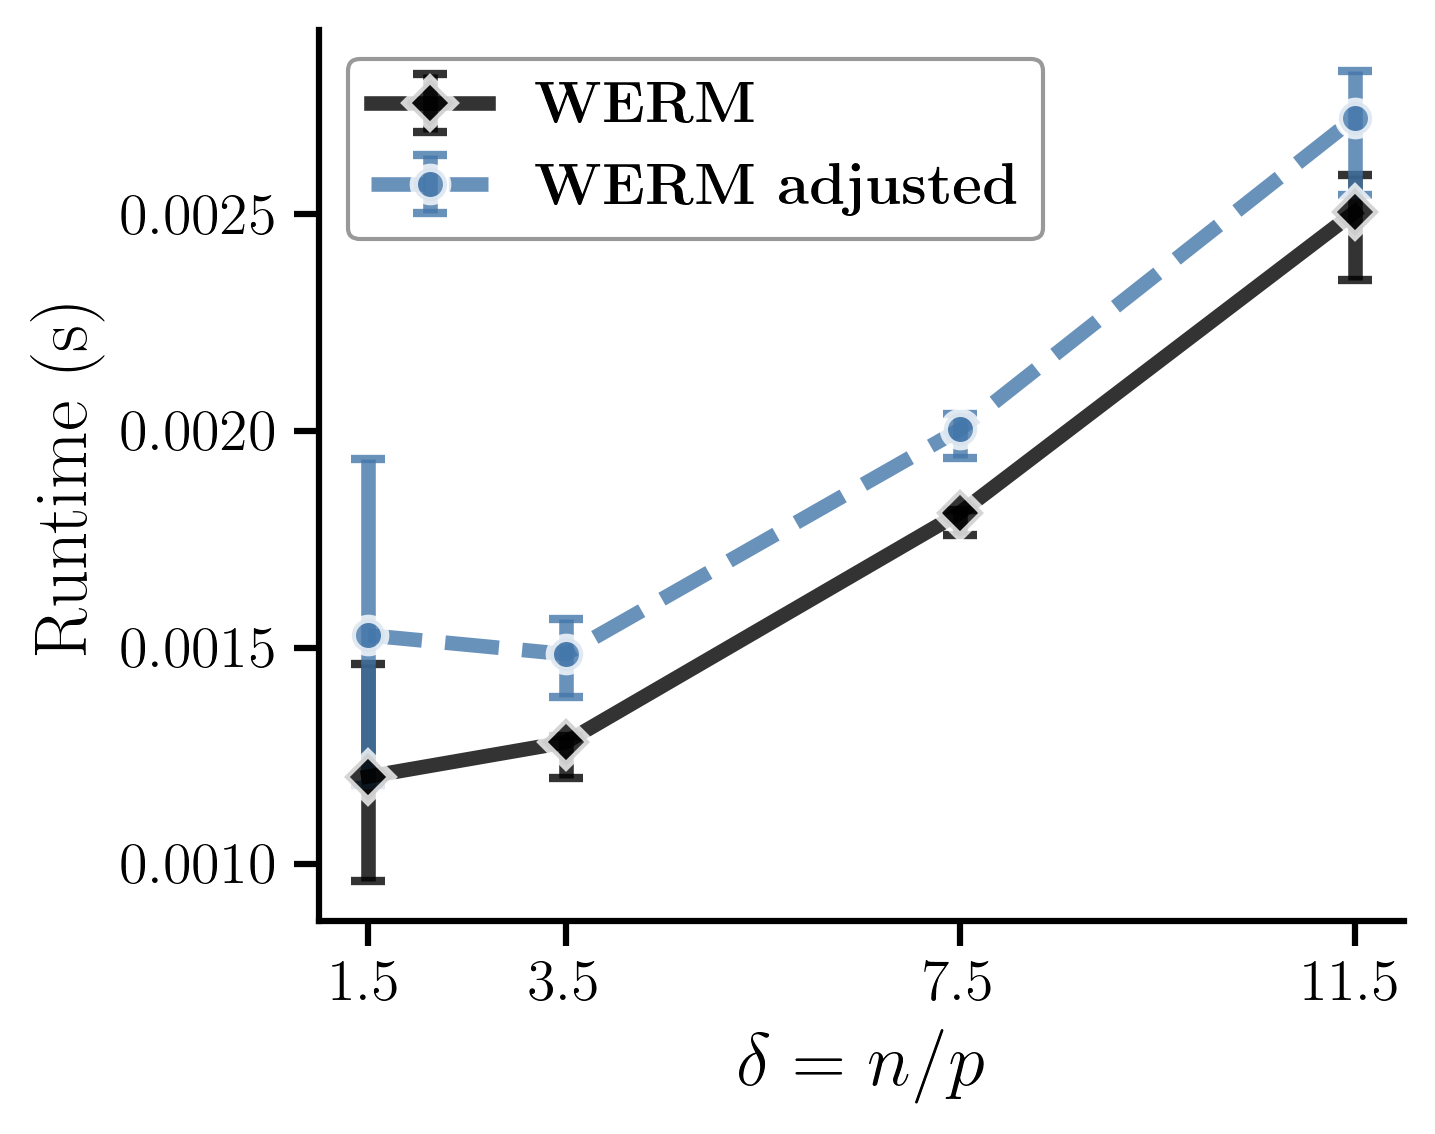

Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


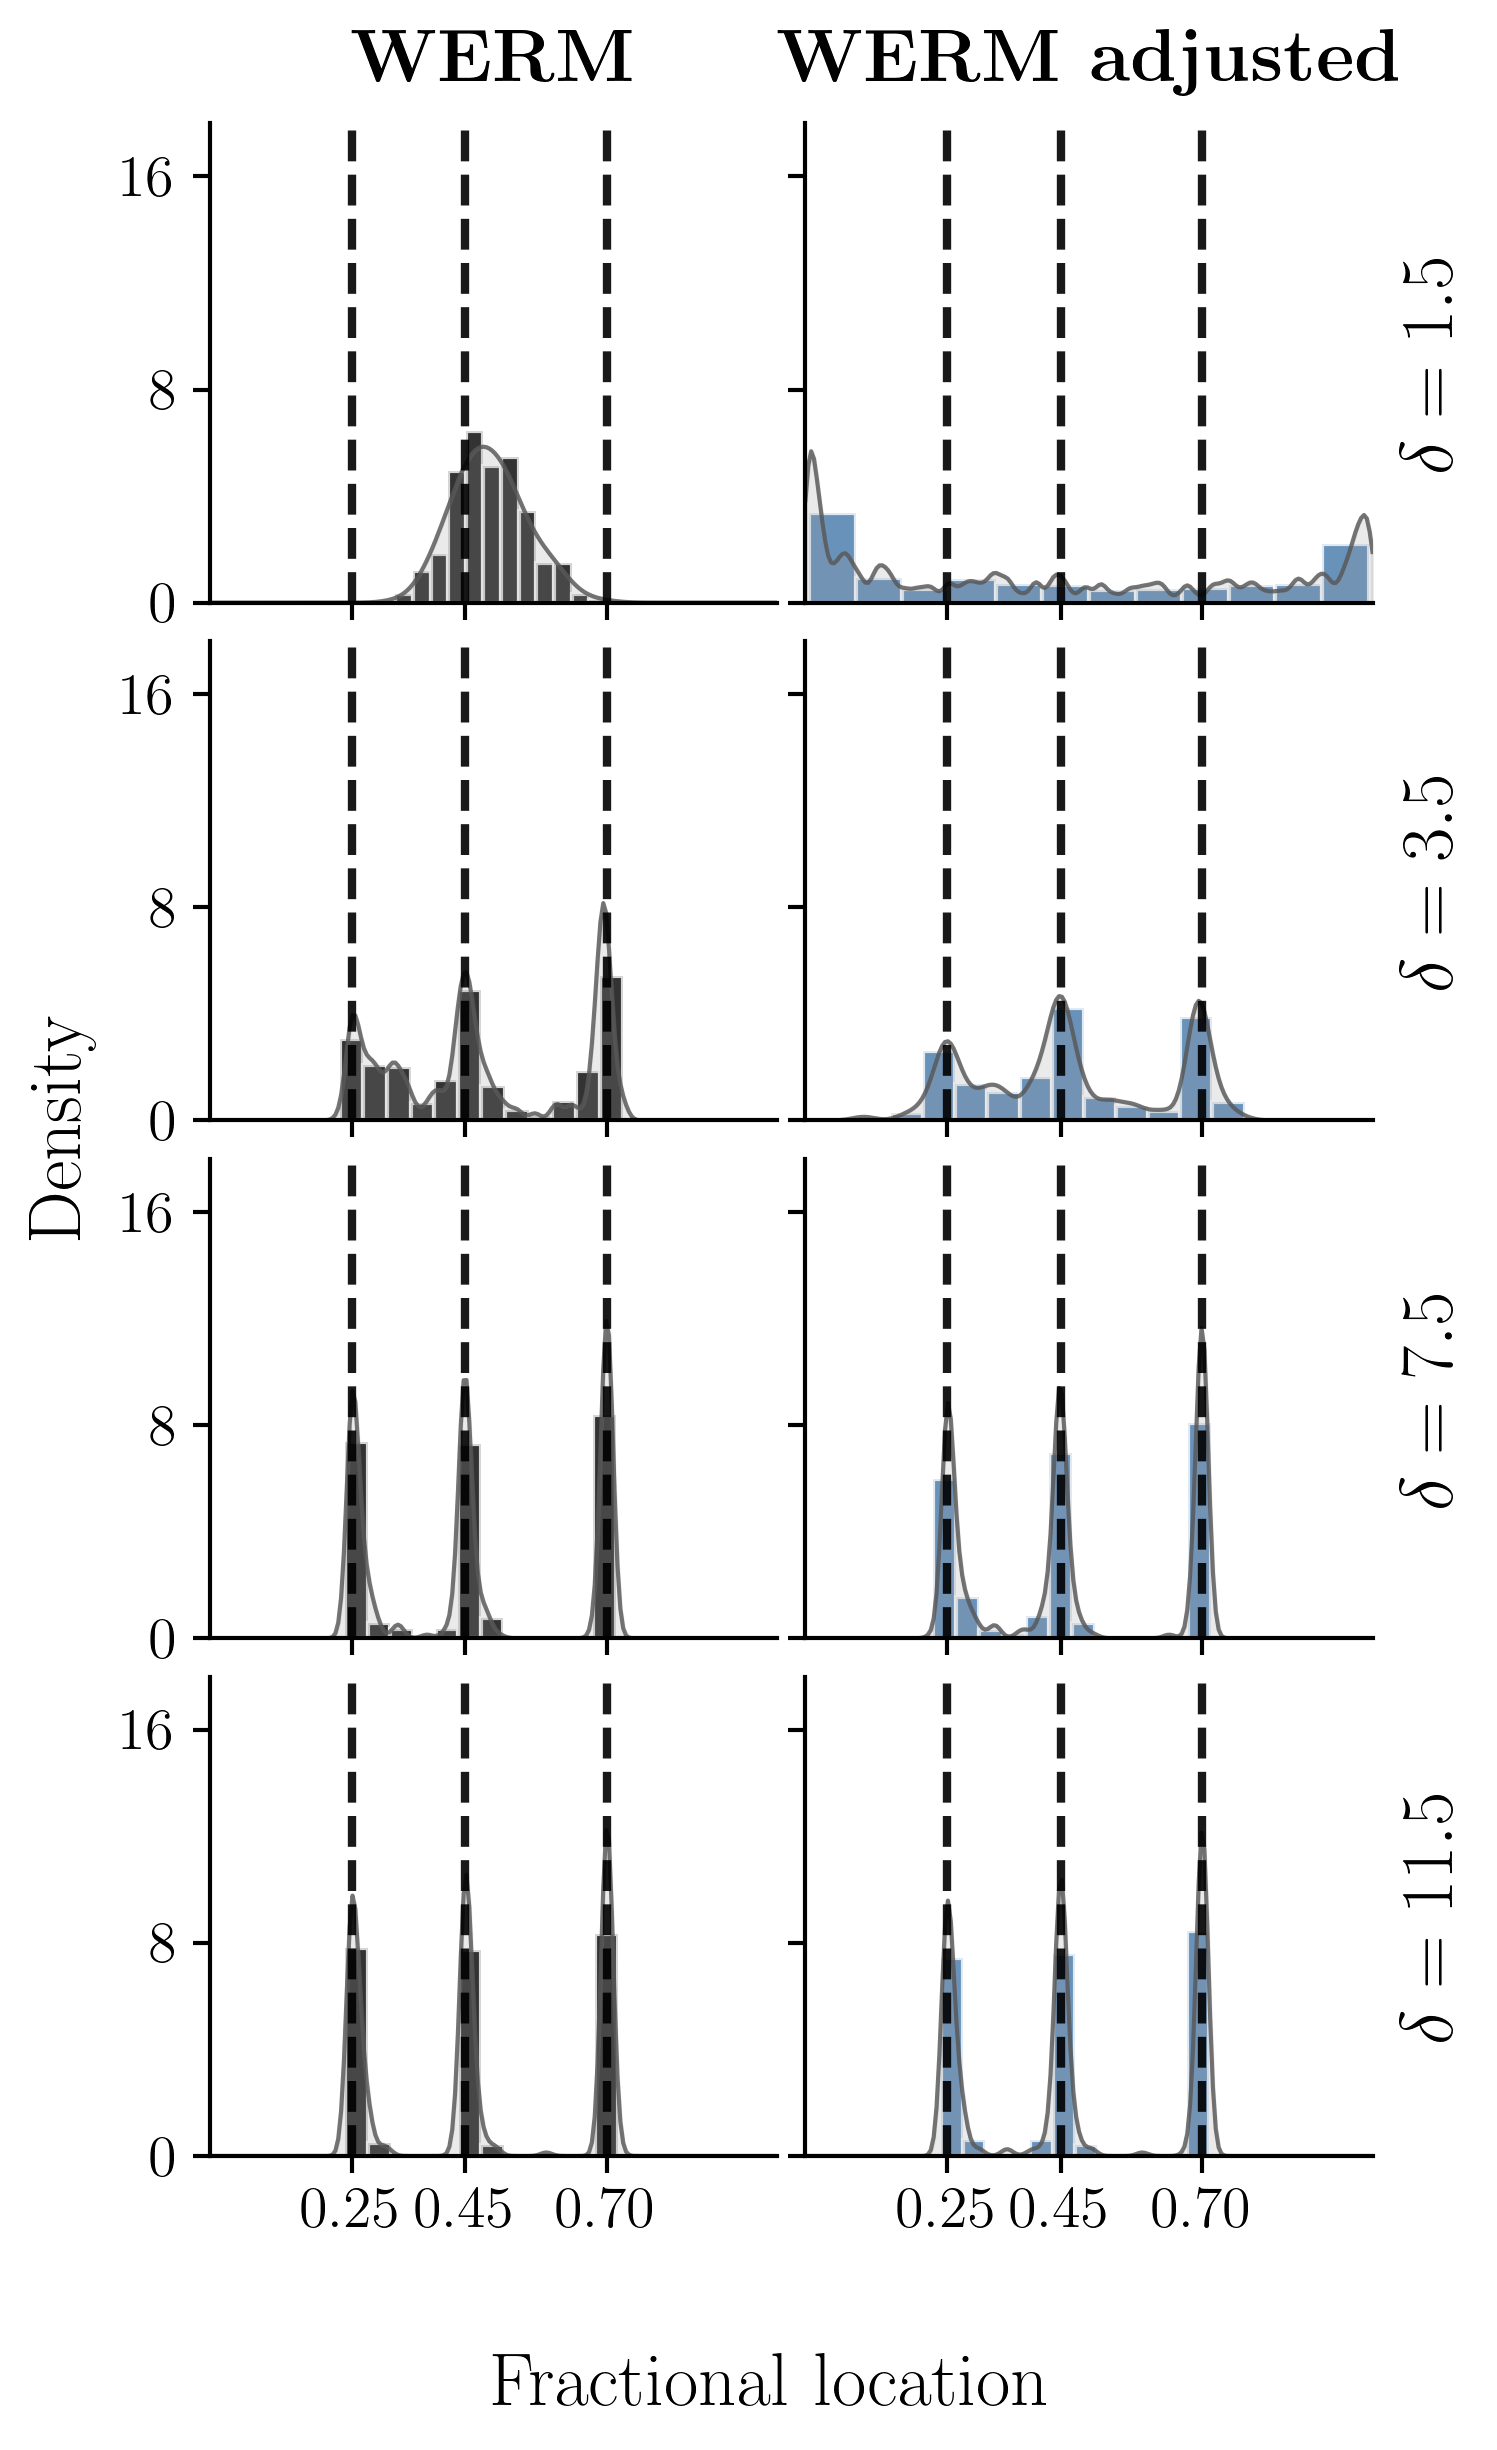

Exported 9 figures to results/M2_adjusted_comparison/ecd9d5c2529d/figures; saved inputs unchanged.


In [6]:
plot_comparison('known')

## Paired localization differences and numerical diagnostics

Differences are **adjusted minus standard** normalized Hausdorff error; positive
values mean worse localization with adjustment. Unknown-count differences are
conditional on **both** methods returning a nonempty estimate. This restriction
is separate from each method's own conditional means above. Counts of excluded
pairs are reported. The known-count comparison includes every successful pair.

In [7]:
paired=[]
for mode,payload in [('unknown',unknown),('known',known)]:
    for i,delta in enumerate(DELTAS):
        records=[r for r in payload['records'] if r['setting']==i]
        differences=np.array([r['methods'][METHODS[1]]['haus']-r['methods'][METHODS[0]]['haus']
            for r in records if all(np.isfinite(r['methods'][m]['haus']) for m in METHODS)])
        paired.append(dict(experiment=mode,delta=delta,paired_nonempty=len(differences),
            excluded_pairs=len(records)-len(differences),mean_adjusted_minus_standard=differences.mean(),
            median_adjusted_minus_standard=np.median(differences),
            adjusted_better=int(np.sum(differences < -1e-12)),
            tied=int(np.sum(np.abs(differences)<=1e-12)),
            adjusted_worse=int(np.sum(differences > 1e-12))))
paired_table=pd.DataFrame(paired)
paired_table.to_csv(DIRECTORY/'paired_localization.csv',index=False)
display(paired_table.round(4))

boundary_rows=[]
for i,delta in enumerate(DELTAS):
    for name in METHODS:
        errors=np.array([(r['methods'][name]['cp']-r['truth'])/r['n']
            for r in known['records'] if r['setting']==i and r['methods'][name]['error'] is None])
        for j,location in enumerate(FRACTIONS['known']):
            boundary_rows.append(dict(delta=delta,method=name,true_fraction=location,
                mean_signed_error=errors[:,j].mean(),mean_absolute_error=np.abs(errors[:,j]).mean()))
boundary_table=pd.DataFrame(boundary_rows)
boundary_table.to_csv(DIRECTORY/'known_boundary_errors.csv',index=False)
display(boundary_table.round(4))
failures=[dict(experiment=mode,delta=DELTAS[r['setting']],trial=r['trial'],method=m,error=f['error'])
          for mode,payload in [('unknown',unknown),('known',known)] for r in payload['records']
          for m,f in r['methods'].items() if f['error'] is not None]
print('Failed method runs:',len(failures))
print('Maximum b-equation residual:',max(unknown_summary.max_b_residual.max(),known_summary.max_b_residual.max()))
if failures: display(pd.DataFrame(failures))
style.verify_sources()

,experiment,delta,paired_nonempty,excluded_pairs,mean_adjusted_minus_standard,median_adjusted_minus_standard,adjusted_better,tied,adjusted_worse
0,unknown,1.5,23,77,0.1017,0.1200,6,4,13
1,unknown,3.5,64,36,-0.0262,0.0000,12,49,3
2,unknown,7.5,100,0,-0.0415,0.0000,45,49,6
3,unknown,11.5,100,0,-0.0474,0.0000,46,53,1
4,known,1.5,100,0,0.0981,0.0767,13,3,84
5,known,3.5,100,0,0.0347,0.0043,10,38,52
6,known,7.5,100,0,0.0072,0.0000,4,73,23
7,known,11.5,100,0,0.0057,0.0000,8,77,15


,delta,method,true_fraction,mean_signed_error,mean_absolute_error
0,1.5,WERM,0.25,0.1955,0.1955
1,1.5,WERM,0.45,0.0435,0.0514
2,1.5,WERM,0.70,-0.1505,0.1505
3,1.5,WERM adjusted,0.25,-0.1295,0.1951
4,1.5,WERM adjusted,0.45,-0.0242,0.2482
5,1.5,WERM adjusted,0.70,0.0826,0.2410
6,3.5,WERM,0.25,0.0479,0.0490
7,3.5,WERM,0.45,0.0135,0.0239
8,3.5,WERM,0.70,-0.0089,0.0150
9,3.5,WERM adjusted,0.25,0.0417,0.0589


Failed method runs: 0
Maximum b-equation residual: 8.104628079763643e-15
Exported 9 figures to results/M2_adjusted_comparison/ecd9d5c2529d/figures; saved inputs unchanged.


## Reproducibility and verification

Implementation: `tools/m2_adjusted_experiment.py`. Tests:
`tests/test_m2_adjusted_experiment.py` verify the fast additive-loss partition search
against the original exact DP (including ties), standard CV scores/counts/locations
against the original M2 helper with identical weights, and the paper's adjustment
against an analytically solvable case. Per-trial artifacts retain data hashes,
CV scores, selected counts, b values/residuals, failures, estimates and timings.
`specification.json` records parameters and source hashes; plotting checks that
saved input artifacts remain unchanged. No original M2 or myocardial result is overwritten.